# 04 - Tiền Xử Lý Ảnh Điện Thoại & Stress Test 4 Cấu Hình trên `data_v2` (38/38 Lớp, 0% Rò Rỉ)

**Dự án:** Chẩn đoán Bệnh trên Lá Cây Nông Nghiệp (`feat/efficientnet-b0-tri`)  
**Mục tiêu:**
1. Xác nhận `data_v2` (`38.039` train / `8.147` valid / `8.098` test) đạt **`0%` rò rỉ UUID/ảnh xoay-lật** trên đủ cả 38 lớp.
2. Minh họa trực quan bộ tiền xử lý `MobileLeafPreprocessor` (**Bilateral Filter + LAB-CLAHE kênh L + Adaptive Unsharp Mask**).
3. Chạy thí nghiệm đối chứng **4 cấu hình (Mốc A → Mốc B → Đối chứng v2 không Preproc → Mốc C)** trên toàn bộ **`8.147` ảnh valid sạch (38/38 lớp)** qua 7 kịch bản suy giảm ảnh chụp điện thoại.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from torchvision import transforms

from mobile_preprocessing_tri import (
    MobileLeafPreprocessor,
    DeterministicLightingShiftPIL,
    DeterministicGaussianNoisePIL,
    DeterministicOcclusionPIL,
)

sns.set_theme(style="whitegrid")
data = json.loads(Path("stress_test_comparison_tri.json").read_text(encoding="utf-8"))
v2_meta = json.loads(Path("efficientnet_b0_robust_tri_results.json").read_text(encoding="utf-8"))

print(f"Bộ dữ liệu: {data['dataset']}")
print(f"Tổng ảnh valid đánh giá: {data['unseen_valid_count']:,} | Sibling leakage: {data['sibling_valid_count']} ({data['sibling_leakage_pct']}%)")
print(f"Held-out Test (8.098 ảnh, 38 lớp) — v1:        {data['v1_heldout_test_8098']}")
print(f"Held-out Test (8.098 ảnh, 38 lớp) — Robust v2: {data['v2_heldout_test_8098']}")

Bộ dữ liệu: data_v2 (0% UUID/sibling leakage, all 38 classes)
Tổng ảnh valid đánh giá: 8,147 | Sibling leakage: 0 (0.0%)
Held-out Test (8.098 ảnh, 38 lớp) — v1:        Macro-F1 99.35% | Acc 99.62% (31/8098 errors)
Held-out Test (8.098 ảnh, 38 lớp) — Robust v2: Macro-F1 99.12% | Acc 99.37% (51/8098 errors)


### Xác nhận Dữ liệu Sạch `data_v2`
Khác với bộ Kaggle Augmented cũ (bị rò rỉ `65,24%` ảnh xoay/lật), toàn bộ **8.147 ảnh valid** và **8.098 ảnh test** của `data_v2` đều được gom nhóm theo chiếc lá gốc (`0%` rò rỉ UUID/Kaggle) và phủ đủ **38/38 lớp**.

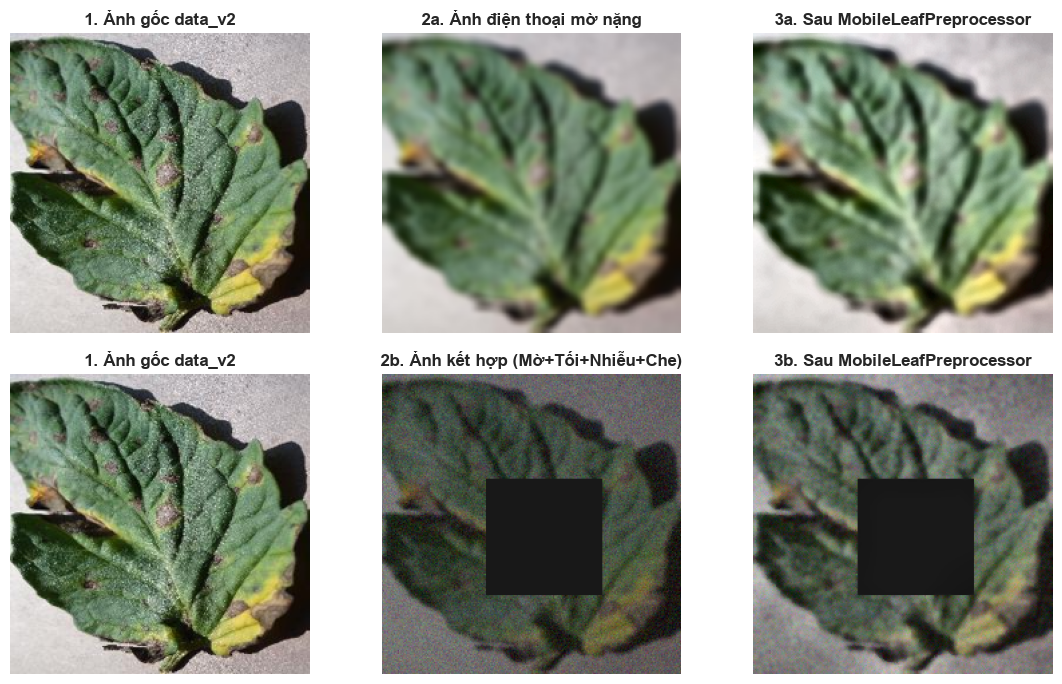

In [2]:
sample = sorted((Path("../data/valid") / "Tomato___Early_blight").glob("*.JPG"))[0]
orig = Image.open(sample).convert("RGB").resize((224, 224))
blur_img = transforms.GaussianBlur(kernel_size=9, sigma=3.0)(orig)
mobile_img = DeterministicOcclusionPIL(0.15)(
    DeterministicGaussianNoisePIL(12.0)(
        DeterministicLightingShiftPIL(0.60, 0.75)(
            transforms.GaussianBlur(kernel_size=5, sigma=1.5)(orig)
        )
    )
)
pre = MobileLeafPreprocessor()
restored_blur = pre(blur_img)
restored_mobile = pre(mobile_img)

fig, axes = plt.subplots(2, 3, figsize=(11.5, 7.0))
items = [
    (orig, "1. Ảnh gốc data_v2"),
    (blur_img, "2a. Ảnh điện thoại mờ nặng"),
    (restored_blur, "3a. Sau MobileLeafPreprocessor"),
    (orig, "1. Ảnh gốc data_v2"),
    (mobile_img, "2b. Ảnh kết hợp (Mờ+Tối+Nhiễu+Che)"),
    (restored_mobile, "3b. Sau MobileLeafPreprocessor"),
]
for ax, (im, title) in zip(axes.flat, items):
    ax.imshow(im)
    ax.set_title(title, fontweight="bold")
    ax.axis("off")
plt.tight_layout()
plt.show()

### Minh họa `MobileLeafPreprocessor` (~2 ms/ảnh)
Lọc nhiễu `Bilateral Filter` + cân bằng sáng cục bộ `CLAHE(clipLimit=1.5)` + `Adaptive Unsharp Mask` chỉ trên kênh sáng `L` của hệ màu **LAB** giúp phục hồi độ rõ đốm bệnh trên ảnh mờ/tối mà không làm sai lệch màu lá trên hai kênh `A, B`.

,Kịch bản,Mốc A: v1 gốc Acc (F1),Mốc B: v1+Preproc (Skew),v2 Robust (ko Preproc),Mốc C: v2+Preproc ★,Lỗi A → C (trên 8.147)
0,clean,99.68% (99.59%),98.55% (97.94%),99.24% (99.02%),99.47% (99.39%),26 → 43
1,blur_mild,97.16% (95.80%),93.56% (91.81%),98.38% (98.07%),99.31% (99.17%),231 → 56
2,harsh_lighting,97.13% (96.82%),95.08% (94.29%),97.05% (96.51%),99.21% (99.00%),234 → 64
3,occlusion_22pct,97.79% (96.86%),90.99% (88.79%),97.35% (96.80%),98.27% (97.47%),180 → 141
4,blur_heavy,68.81% (63.86%),67.87% (63.83%),95.32% (93.82%),98.65% (98.28%),"2,541 → 110"
5,sensor_noise,67.78% (63.55%),61.97% (61.43%),97.78% (96.85%),98.92% (98.60%),"2,625 → 88"
6,combined_mobile,31.74% (27.92%),16.53% (17.34%),77.59% (73.63%),95.41% (93.94%),"5,561 → 374"


C:\Users\VÕ MINH TRI\AppData\Local\Temp\ipykernel_26016\2848057421.py:42: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  plt.tight_layout()


D:\plant-disease-ml\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


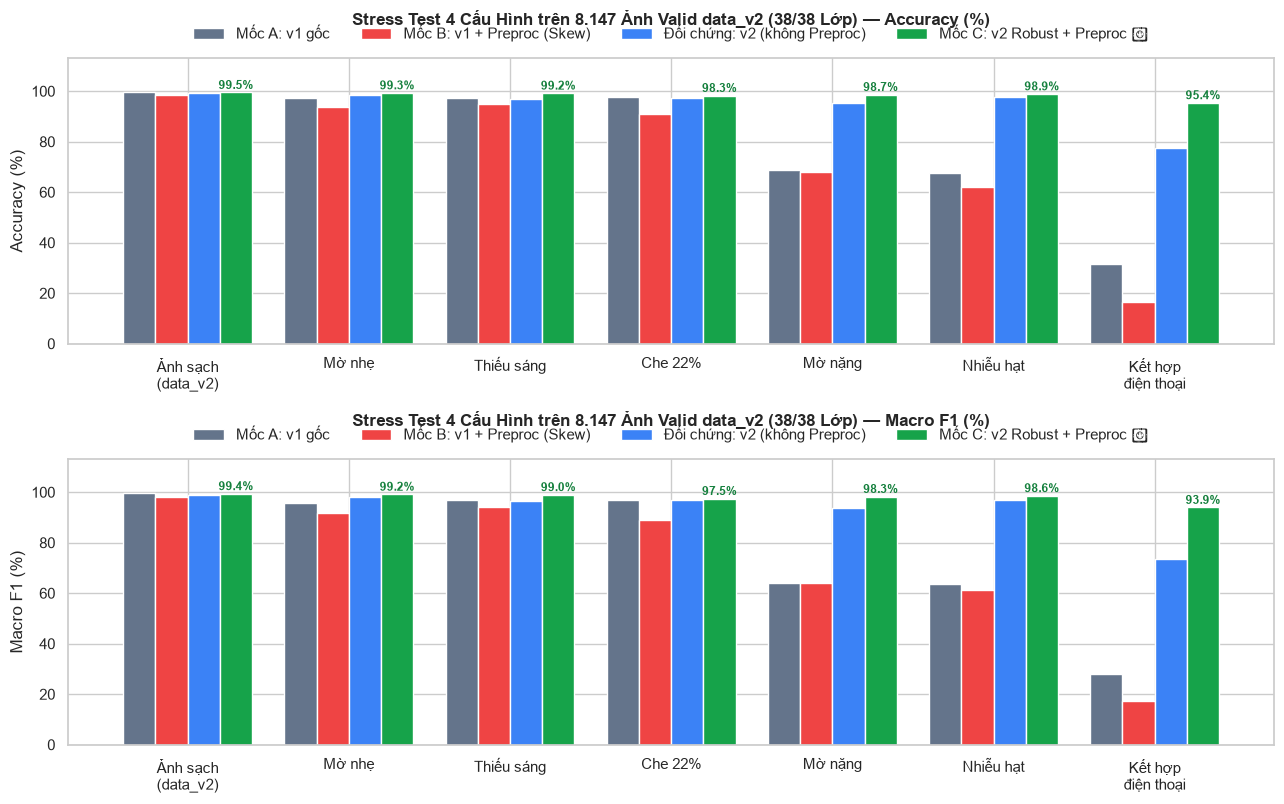

In [3]:
scenarios = ["clean", "blur_mild", "harsh_lighting", "occlusion_22pct", "blur_heavy", "sensor_noise", "combined_mobile"]
rows = []
for s in scenarios:
    a = data["v1_raw"][s]
    b = data["v1_with_preproc"][s]
    vr = data["v2_robust_raw"][s]
    c = data["v2_robust_with_preproc"][s]
    rows.append({
        "Kịch bản": s,
        "Mốc A: v1 gốc Acc (F1)": f"{a['accuracy']*100:.2f}% ({a['macro_f1']*100:.2f}%)",
        "Mốc B: v1+Preproc (Skew)": f"{b['accuracy']*100:.2f}% ({b['macro_f1']*100:.2f}%)",
        "v2 Robust (ko Preproc)": f"{vr['accuracy']*100:.2f}% ({vr['macro_f1']*100:.2f}%)",
        "Mốc C: v2+Preproc ★": f"{c['accuracy']*100:.2f}% ({c['macro_f1']*100:.2f}%)",
        "Lỗi A → C (trên 8.147)": f"{a['errors']:,} → {c['errors']:,}",
    })
display(pd.DataFrame(rows))

labels = ["Ảnh sạch\n(data_v2)", "Mờ nhẹ", "Thiếu sáng", "Che 22%", "Mờ nặng", "Nhiễu hạt", "Kết hợp\nđiện thoại"]
x = np.arange(len(scenarios))
w = 0.20
fig, axes = plt.subplots(2, 1, figsize=(13, 8.2))
for ax, key, title, ylabel in [
    (axes[0], "accuracy", "Stress Test 4 Cấu Hình trên 8.147 Ảnh Valid data_v2 (38/38 Lớp) — Accuracy (%)", "Accuracy (%)"),
    (axes[1], "macro_f1", "Stress Test 4 Cấu Hình trên 8.147 Ảnh Valid data_v2 (38/38 Lớp) — Macro F1 (%)", "Macro F1 (%)"),
]:
    va = [data["v1_raw"][s][key] * 100 for s in scenarios]
    vb = [data["v1_with_preproc"][s][key] * 100 for s in scenarios]
    vr = [data["v2_robust_raw"][s][key] * 100 for s in scenarios]
    vc = [data["v2_robust_with_preproc"][s][key] * 100 for s in scenarios]
    ax.bar(x - 1.5*w, va, width=w, color="#64748b", label="Mốc A: v1 gốc")
    ax.bar(x - 0.5*w, vb, width=w, color="#ef4444", label="Mốc B: v1 + Preproc (Skew)")
    ax.bar(x + 0.5*w, vr, width=w, color="#3b82f6", label="Đối chứng: v2 (không Preproc)")
    bc = ax.bar(x + 1.5*w, vc, width=w, color="#16a34a", label="Mốc C: v2 Robust + Preproc ★")
    for b in bc:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 1.4, f"{b.get_height():.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#15803d")
    ax.set_title(title, fontweight="bold", pad=24)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 113)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### Kết Luận Thực Nghiệm trên `data_v2` (Đủ 38/38 Lớp, 0% Rò Rỉ)
1. **Ảnh điện thoại đánh gục mô hình `v1` học ảnh sạch (Mốc A):** Trên `combined_mobile`, `v1` tụt từ `99,59%` xuống chỉ còn **`27,92%` Macro-F1 (`31,74%` Acc, sai `5.561 / 8.147` ảnh)**.
2. **Minh chứng *Training-Serving Skew* (Mốc B):** Bật `MobileLeafPreprocessor` lúc suy luận mà không train đồng nhất khiến `combined_mobile` tiếp tục sập xuống **`17,34%` Macro-F1 (`16,53%` Acc)**.
3. **Đột phá của `Robust v2 + MobileLeafPreprocessor` (Mốc C):**
   - `combined_mobile`: nhảy vọt từ **`27,92%` → `93,94%` Macro-F1 (+66,02%)** và **`31,74%` → `95,41%` Accuracy (+63,67%)**, cắt giảm **`93,3%` tổng số lỗi** (`5.561` → `374`).
   - `blur_heavy`: **`63,86%` → `98,28%` Macro-F1 (+34,42%)**; `sensor_noise`: **`63,55%` → `98,60%` Macro-F1 (+35,05%)**.
   - So với đối chứng `v2` tắt bộ lọc (`73,63%` F1 trên `combined_mobile`), riêng `MobileLeafPreprocessor` đóng góp thêm **`+20,31%` Macro-F1** và **`+17,82%` Accuracy**.
   - Đồng thời trên tập held-out `data/test/` (**8.098 ảnh**, 38 lớp) vẫn giữ **`99,12%` Macro-F1** (`99,37%` Accuracy).